# 06 · 图像输入：做一个有证据的照片分享助手

收到一张照片，程序先识别**能看见什么**，再按用户明确选择的回应方式组织消息。
本册用四张照片风格素材和五张小鲸鱼贴纸，体验图片如何进入 state、instructions 与 criteria。

| 实验 | 变化与参照 | 可以检查什么 |
|---|---|---|
| 照片放 state | 四张固定图片，仅发送像素 | 可见人脸与主体构图 |
| 参考图放 instructions | 相同/不同贴纸，参考不变 | 两图对照及问题局部证据 |
| 候选图放 criteria | 已知贴纸与不匹配图 | 图片定义选项，保留 none 出口 |
| 亮度探针 | 同一张图，亮度三个档位 | 当前图片的人脸判断是否变化 |
| 多帧 state + Score | 相同帧集合，只改变顺序 | 最新一帧与有序等级的含义 |
| 图片放置与 token | 同图、同任务，共享/逐问题重复 | 两个请求的总 input_tokens |
| 协议负例 | 缺开关、宽度 279 像素 | 是否出现预期的 HTTP 拒绝 |

**运行状态：本文件已执行真实 API，并核对输出与图片；具体模型、时间与响应见末尾记录。** 旧版输出见
[归档](images_records/legacy-before-20261017.json)，不替代本版实验。

理论依据：[官方 Images](https://docs.typesafe.ai/images)、[Score](https://docs.typesafe.ai/primitives/score)、
[知识库 42 号](../11_知识库/jev-cookbook/42-jev-1-14/article.md)，接口于 2026-10-17 核对。
图像仍属 dreamer-ready 实验特性，接口和效果可能变化。

## 0. 准备与来源

需要 Python≥3.10、typesafe-sdk≥0.7.5、Pillow、nbformat 和 nbclient。依赖安装见 main/README。
本册不执行安装或升级；API 密钥只从进程环境 TYPESAFE_API_KEY 读取。

默认 JEV_RUN_MODE=live，任何意外请求失败都会停止。人工演示需显式设置 JEV_RUN_MODE=offline，
不会因缺密钥或 401 自动换答案。密钥位于项目根目录 .env 时，可在 main/ 运行：

    .venv/bin/python generators/execute_images_notebook.py --mode live --env-file ../.env

预设 15 次业务请求、23 个问题，另有 2 次预期拒绝探针，禁用自动重试。

In [1]:
import hashlib
import json
import math
import os
from datetime import datetime, timezone
from importlib.metadata import version
from io import BytesIO
from pathlib import Path

from IPython.display import Image as DisplayImage, Markdown, display
from PIL import Image as PILImage, ImageDraw, ImageEnhance, ImageOps
from typesafe_sdk import (Choice, Image, Noul, Score, SystemOneResponse,
                         TypeSafeClient, TypeSafeAPIError, RetryPolicy)

MODE = os.environ.get("JEV_RUN_MODE", "live")
if MODE not in {"live", "offline"}:
    raise ValueError("JEV_RUN_MODE 只能是 live 或 offline")
KEY = os.environ.get("TYPESAFE_API_KEY", "")
if MODE == "live" and not KEY:
    raise RuntimeError("缺少 TYPESAFE_API_KEY；演示请显式选择 offline")
MODEL = "jev-1.14.0"
HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
client = (TypeSafeClient(api_key=KEY, model=MODEL, timeout=45,
                         retry=RetryPolicy(max_retries=0)) if MODE == "live" else None)
CALLS, PROBES, ASSET_INFO = [], [], {}
print(f"来源={MODE} | 模型={MODEL} | SDK={version('typesafe-sdk')}")

来源=live | 模型=jev-1.14.0 | SDK=0.7.5


### 0.1 素材和标签先固定

[images_manifest.json](scenes/images_manifest.json) 保存图片尺寸、SHA-256 和目视复核的可见事实。
照片是生成素材；“生图想表达什么”不是发送者意图的真值，单人标注也不是独立测试金标。

实际贴纸配字为“抱抱”“已老实，求放过”“狗头保命”“绝了绝了”“已装死，请自便”。
英文文件名是资源 ID，不代表图片内容；模型不会收到这些文件名或评测标签。

In [2]:
def find_chapter():
    if os.environ.get("JEV_IMAGES_DIR"):
        return Path(os.environ["JEV_IMAGES_DIR"]).resolve()
    for root in (Path.cwd(), *Path.cwd().parents):
        for rel in ("", "02_核心概念", "main/02_核心概念"):
            path = root / rel
            if (path / "scenes/images_manifest.json").is_file():
                return path
    raise FileNotFoundError("找不到素材；请设置 JEV_IMAGES_DIR")

CHAPTER = find_chapter()
MANIFEST = json.loads((CHAPTER / "scenes/images_manifest.json").read_text())

def load(item):
    path = CHAPTER / item["file"]
    if hashlib.sha256(path.read_bytes()).hexdigest() != item["sha256"]:
        raise ValueError("素材已变化，需要重新核对并版本化标签")
    with PILImage.open(path) as image:
        if list(image.size) != item["size"]:
            raise ValueError("尺寸与素材清单不一致")
        return ImageOps.exif_transpose(image).convert("RGB")

PHOTOS = {k: load(v) for k, v in MANIFEST["photos"].items()}
STICKERS = {k: load(v) for k, v in MANIFEST["stickers"].items()}

### 0.2 预处理属于调用方

当前官方限制为 PNG/JPEG 静态图、每边 280–1568 像素、单图≤16 MiB，总像素≤2,458,624。
API 不会自动把越界图片缩放到合规尺寸；EXIF 朝向需先转成实际像素方向。

以下助手从内存 PNG 创建 Image，避免临时路径依赖。预览输出为 JPEG，只缩放显示，不改变模型输入。

In [3]:
def asset(image, name, validate=True):
    buffer = BytesIO()
    image.save(buffer, format="PNG")
    data = buffer.getvalue()
    if validate and (not all(280 <= x <= 1568 for x in image.size)
                     or image.width * image.height > 2458624 or len(data) > 16*1024**2):
        raise ValueError("图片不满足本册核对的官方限制")
    result = Image(data)
    ASSET_INFO[str(result)] = {"name": name, "size": list(image.size),
                              "sha256": hashlib.sha256(data).hexdigest()}
    return result

def preview(images, width=200):
    thumbs = []
    for image in images:
        copy = image.copy()
        copy.thumbnail((width, 320))
        thumbs.append(copy)
    canvas = PILImage.new("RGB", (len(thumbs)*(width+8), 340), "white")
    for i, image in enumerate(thumbs):
        canvas.paste(image, (i*(width+8), 0))
    buffer = BytesIO()
    canvas.save(buffer, format="JPEG", quality=85)
    display(DisplayImage(data=buffer.getvalue(), format="jpeg"))

### 0.3 一次请求共享 state，问题与答案按 ID 对应

state 中的图片供所有问题读取；instructions 中的参考图属于那个问题；
criteria 中的图片定义选项。每出现一次图片引用，都会增加模型读取的图像内容。

调用记录保存图像哈希、问题、响应和 token 用量，不保存密钥或图像 base64。
共享一张图并不意味着任意数量问题的请求成本恒定。

In [4]:
def audit_value(value):
    if isinstance(value, Image):
        return {"image": ASSET_INFO[str(value)]}
    if isinstance(value, str) and value in ASSET_INFO:
        return {"image": ASSET_INFO[value]}
    if isinstance(value, dict):
        return {str(k): audit_value(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [audit_value(v) for v in value]
    return value

def call(label, state, questions):
    started = datetime.now(timezone.utc).isoformat()
    if MODE == "offline":
        response = SystemOneResponse.model_validate({
            "model": "offline-demo", "answers": OFFLINE[label],
            "usage": {"input_tokens": 6100 if label == "cost_duplicate" else 3000,
                      "output_tokens": 0}})
    else:
        response = client.system_one(state, questions, extra_headers=HEADERS)
    validate(response, questions)
    CALLS.append({"label": label, "source": MODE, "started_at_utc": started,
                  "state": audit_value(state),
                  "questions": audit_value({k: q.model_dump(mode="json") for k, q in questions.items()}),
                  "response": response.model_dump(mode="json")})
    return response

### 0.4 离线答案必须完整且明确标为人工

演示数据只为让分析代码和分支可运行。Choice 保留全部选项，Score 保留 legend 与 probabilities；
不像旧版替身只留下几个选项，也不让概率质量超过 1。下面数字不是模型预测。

In [5]:
def noun(value):
    return {"type": "noul", "noul": value}

def choice(probabilities):
    return {"type": "choice", "choice": max(probabilities, key=probabilities.get),
            "probabilities": probabilities, "confidence": 0.8}

SCENES = ("person_photo", "food_table", "outdoor_scene", "other")
def scene_answer(correct):
    return choice({k: .94 if k == correct else .02 for k in SCENES})

def photo_answer(face, composition):
    return {"face": noun(.96 if face else .04),
            "composition": scene_answer(composition)}

OFFLINE = {key: photo_answer(item["face"], item["composition"])
           for key, item in MANIFEST["photos"].items() if key != "neutral_face"}
OFFLINE.update({"reference_same": {"same": noun(.97)},
                "reference_different": {"same": noun(.03)},
                **{f"light_{k}": {"face": noun(v)} for k, v in
                   (("dim", .94), ("original", .96), ("bright", .95))}})
for label, expected in (("sticker_known", "bear_hug"), ("sticker_none", "none")):
    options = [*STICKERS, "none"]
    OFFLINE[label] = {"match": choice({k: .9 if k == expected else .02 for k in options})}

Score 的列表按 **0 开始**编码。列表里写“1 冷静”只是描述文字，不能把实际 0–4 的数值当成 1–5。
本册在门的例子中明确用 0=关闭、1=半开、2=全开；期望分数可以是小数。

In [6]:
DOOR_LEVELS = ["门完全关闭，门板遮住门洞。",
               "门部分打开，仍有门板遮住部分门洞。",
               "门完全打开，门洞基本敞开。"]

def door_demo(probabilities, closed):
    return {"closed": noun(closed), "openness": {
        "type": "score", "score": sum(int(k)*p for k, p in probabilities.items()),
        "confidence": .8, "legend": dict(enumerate(DOOR_LEVELS)),
        "probabilities": probabilities}}

OFFLINE["ended_closed"] = door_demo({0: .9, 1: .08, 2: .02}, .96)
OFFLINE["ended_open"] = door_demo({0: .02, 1: .08, 2: .9}, .04)
for label in ("cost_shared", "cost_duplicate"):
    OFFLINE[label] = photo_answer(True, "person_photo")

### 0.5 响应结构与概率检查

这些检查发现字段或量表错误，不证明语义正确或概率已校准。
API 可能把概率显示为有限小数，因此允许总和与期望值有小量舍入误差，保留原始值，不悄悄归一化。

In [7]:
def validate(response, questions):
    if set(response.answers) != set(questions):
        raise ValueError("答案 ID 与问题不一致")
    for key, answer in response.answers.items():
        if answer.type != questions[key].type:
            raise ValueError("答案类型与问题不一致")
        if answer.type == "noul":
            if not 0 <= answer.noul <= 1:
                raise ValueError("Noul 超出概率范围")
            continue
        probabilities = answer.probabilities
        if any(not 0 <= p <= 1 for p in probabilities.values()):
            raise ValueError("概率越界")
        if abs(sum(probabilities.values())-1) > .021:
            raise ValueError("概率质量不接近 1")
        if answer.type == "choice" and set(probabilities) != set(questions[key].criteria):
            raise ValueError("Choice 缺少选项")
        if answer.type == "score":
            expected = sum(float(k)*p for k, p in probabilities.items())
            if abs(expected-answer.score) > .031:
                raise ValueError("Score 与概率期望不一致")

def table(rows):
    keys = list(rows[0])
    lines = ["| " + " | ".join(keys) + " |", "|" + "---|"*len(keys)]
    lines += ["| " + " | ".join(str(row[k]) for k in keys) + " |" for row in rows]
    display(Markdown(chr(10).join(lines)))

## 1. 图片放 state：先确认能看见什么

四张图依次为咖啡馆人物、办公室人物、早午餐餐桌、河边日落。
问题是“是否有清楚可见的人脸”和“画面主体属于哪类”，不推断发送者在想什么。

标签只用于评测；state 不再包含“疲惫、想被夸、期待邀请”等文字描述。

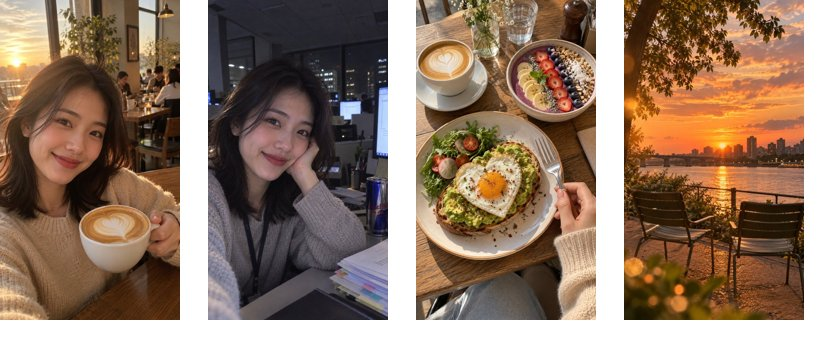

In [8]:
PHOTO_KEYS = ("cafe_selfie", "overtime_night", "brunch_table", "sunset_chairs")
PHOTO_ASSETS = {k: asset(PHOTOS[k], k) for k in PHOTO_KEYS}
PHOTO_QUESTIONS = {
    "face": Noul(instructions="照片 photo 中是否有清楚可见的人脸？"),
    "composition": Choice(instructions="照片 photo 的画面主体属于哪一类？", criteria={
        "person_photo": "主体是人物，人脸清楚可见。",
        "food_table": "主体是食物或餐桌，没有清楚可见的人脸。",
        "outdoor_scene": "主体是户外景观，没有清楚可见的人脸或作为主体的食物。",
        "other": "不属于上述类型，或画面无法确定。"}),
}
preview([PHOTOS[k] for k in PHOTO_KEYS])

### 1.1 固定问题，逐张请求

所有样本使用相同 questions；不把文件名、标签、素材描述或生图提示词送给模型。
模型判断有误时保留该样本，不靠增加暗示文字制造正确输出。

In [9]:
PHOTO_RESULTS = {}
for key in PHOTO_KEYS:
    response = call(key, {"photo": PHOTO_ASSETS[key]}, PHOTO_QUESTIONS)
    PHOTO_RESULTS[key] = response.answers
    print(key, "完成；来源=", MODE)

cafe_selfie 完成；来源= live


overtime_night 完成；来源= live


brunch_table 完成；来源= live


sunset_chairs 完成；来源= live


### 1.2 逐样本核对，不只看 argmax

Noul 用预先固定的 0.5 作人脸判断阈值；Choice 与人工构图标签比较。
概率、confidence 与正确性分别呈现。四张生成素材不是通用视觉基准。

In [10]:
PHOTO_ROWS = []
for key, answers in PHOTO_RESULTS.items():
    reference = MANIFEST["photos"][key]
    selected = answers["composition"]
    PHOTO_ROWS.append({"素材": key, "P(人脸)": answers["face"].noul,
        "人脸标签": reference["face"], "人脸命中": (answers["face"].noul >= .5) == reference["face"],
        "构图选择": selected.choice, "构图标签": reference["composition"],
        "构图命中": selected.choice == reference["composition"],
        "confidence": selected.confidence})
table(PHOTO_ROWS)
print("完整概率：", {k: a["composition"].probabilities for k, a in PHOTO_RESULTS.items()})

| 素材 | P(人脸) | 人脸标签 | 人脸命中 | 构图选择 | 构图标签 | 构图命中 | confidence |
|---|---|---|---|---|---|---|---|
| cafe_selfie | 0.99 | True | True | person_photo | person_photo | True | 1.0 |
| overtime_night | 0.99 | True | True | person_photo | person_photo | True | 1.0 |
| brunch_table | 0.01 | False | True | food_table | food_table | True | 1.0 |
| sunset_chairs | 0.01 | False | True | outdoor_scene | outdoor_scene | True | 1.0 |

完整概率： {'cafe_selfie': {'person_photo': 1.0, 'food_table': 0.0, 'outdoor_scene': 0.0, 'other': 0.0}, 'overtime_night': {'person_photo': 1.0, 'food_table': 0.0, 'outdoor_scene': 0.0, 'other': 0.0}, 'brunch_table': {'person_photo': 0.0, 'food_table': 1.0, 'outdoor_scene': 0.0, 'other': 0.0}, 'sunset_chairs': {'person_photo': 0.0, 'food_table': 0.0, 'outdoor_scene': 1.0, 'other': 0.0}}


### 解释边界

识别“自拍、食物、风景”不等于识别分享动机，更不等于了解照片中人的真实情绪。
若要选择回复方式，应加入发送者明确说的话或让用户选择目标，不能用生图设定给“猜心”打准确率。

## 2. 参考图放 instructions：相同图案吗

把“抱抱”贴纸作为问题专用参考图，分别比较它本身与“已装死，请自便”贴纸。
真值来自源图选择；比较对象是图案，不是人物身份，也不涉及推断聊天意图。

参考图片在 instructions 的结构化对象中；state 仍然只含待比对的 photo。

In [11]:
REFERENCE = asset(STICKERS["rua_you"], "reference_hug")
REFERENCE_QUESTION = {"same": Noul(instructions={
    "task": "待比较图片 photo 中的图案与 reference 的图案相同吗？允许边框或缩放变化。",
    "reference": REFERENCE})}
REFERENCE_CASES = {
    "reference_same": ("rua_you", True),
    "reference_different": ("ride_bear", False),
}
REFERENCE_ROWS = []
for label, (key, expected) in REFERENCE_CASES.items():
    result = call(label, {"photo": asset(STICKERS[key], label)}, REFERENCE_QUESTION)
    p = result.answers["same"].noul
    REFERENCE_ROWS.append({"样本": label, "P(相同)": p,
                           "已知关系": expected, "命中": (p >= .5) == expected})

问题专用参考图适合样品核对、图案比较等场景。若多个问题共用同一张图，可移到 state 避免逐问题重复读取。
这里的正负例非常简单，只说明这两个固定图案的表现。

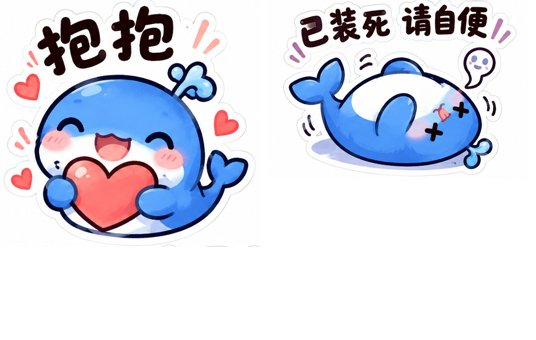

| 样本 | P(相同) | 已知关系 | 命中 |
|---|---|---|---|
| reference_same | 0.99 | True | True |
| reference_different | 0.01 | False | True |

In [12]:
preview([STICKERS["rua_you"], STICKERS["ride_bear"]], width=260)
table(REFERENCE_ROWS)

## 3. 候选图放 criteria：从贴纸库匹配图案

五个选项直接用图片定义，另加 none。把已知贴纸等比缩小、放到白色画布，再询问匹配哪一张。
另用红色圆形作不匹配样本。

这是可核对的视觉匹配实验。它不评价“哪个表情包最适合回复某人”，后者需要使用者偏好与对话背景。

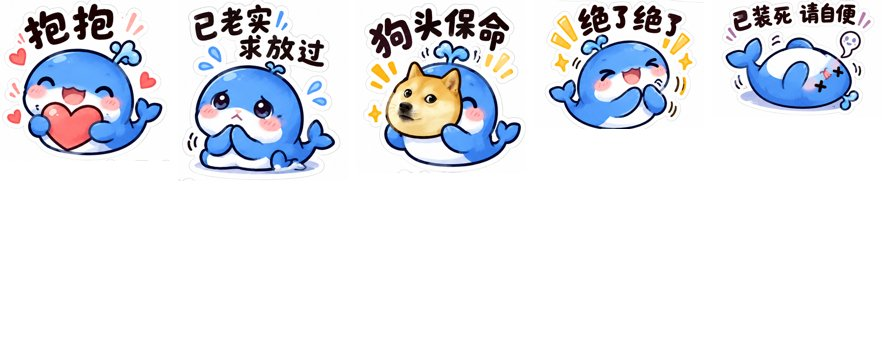

配字： {'rua_you': '抱抱', 'fake_cry': '已老实，求放过', 'angry_pout': '狗头保命', 'bear_hug': '绝了绝了', 'ride_bear': '已装死，请自便'}


In [13]:
STICKER_OPTIONS = {k: asset(image, f"option_{k}") for k, image in STICKERS.items()}
STICKER_QUESTION = {"match": Choice(
    instructions="图片 photo 中的图案最匹配哪个候选图片？比较图案与文字，不匹配则选 none。",
    criteria={**STICKER_OPTIONS, "none": "与所有候选图片都不匹配。"})}
query = PILImage.new("RGB", (640, 520), "white")
thumb = STICKERS["bear_hug"].copy()
thumb.thumbnail((390, 340))
query.paste(thumb, (130, 100))
unknown = PILImage.new("RGB", (400, 400), "white")
ImageDraw.Draw(unknown).ellipse((90, 90, 310, 310), fill=(205, 75, 70))
STICKER_CASES = {"sticker_known": (query, "bear_hug"),
                 "sticker_none": (unknown, "none")}
preview(STICKERS.values(), width=170)
print("配字：", {k: v["caption"] for k, v in MANIFEST["stickers"].items()})

### 3.1 真的检查 none 出口

选项里有 none 不保证模型会使用它，必须提供不匹配样本检查。
状态中没有“这是哪张贴纸”的文字答案，候选文件名也不会送入 state。

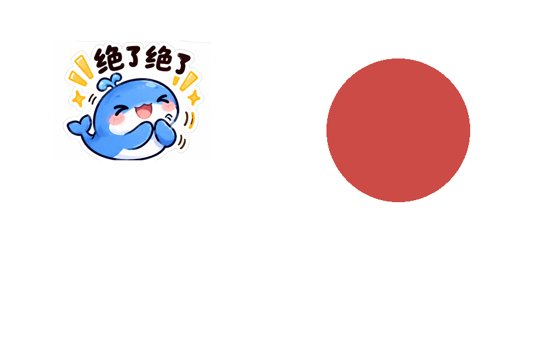

| 样本 | 选择 | 源图标签 | 命中 | confidence |
|---|---|---|---|---|
| sticker_known | bear_hug | bear_hug | True | 0.98 |
| sticker_none | none | none | True | 1.0 |

In [14]:
STICKER_ROWS = []
for label, (image, expected) in STICKER_CASES.items():
    response = call(label, {"photo": asset(image, label)}, STICKER_QUESTION)
    answer = response.answers["match"]
    STICKER_ROWS.append({"样本": label, "选择": answer.choice, "源图标签": expected,
                         "命中": answer.choice == expected, "confidence": answer.confidence})
preview([query, unknown], width=260)
table(STICKER_ROWS)

### 怎样读候选图的作用

图片使选项带上具体视觉定义，但此实验没有“文字选项 vs 图片选项”的对照，不能宣称加图提高了准确率。
源图匹配也比开放场景推荐简单得多；若目标变成推荐，应另行定义评估标准。

## 4. 亮度探针：同一张脸是否还能被看见

沿用中性基准照，创建 ×0.65、×1.00、×1.35 三档亮度。
本次问题固定为“是否有清楚可见的人脸”，不把概率变化解释成照片中人更开心或心情改变。

所有变体在内存中以相同格式编码；改变亮度会改变像素、对比与饱和细节，不能把它等同于现实照明实验。

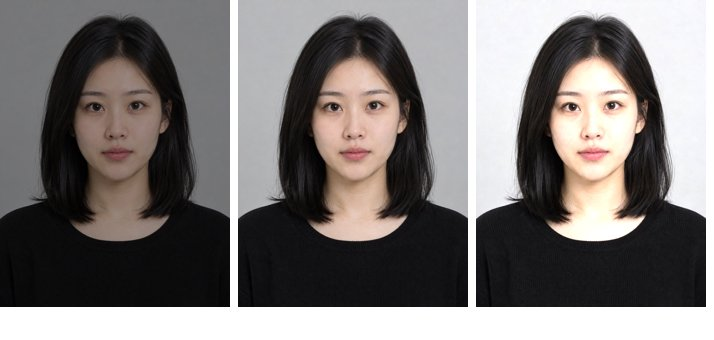

In [15]:
LIGHT_IMAGES = {name: ImageEnhance.Brightness(PHOTOS["neutral_face"]).enhance(factor)
                for name, factor in (("dim", .65), ("original", 1.0), ("bright", 1.35))}
LIGHT_QUESTION = {"face": PHOTO_QUESTIONS["face"]}
preview(LIGHT_IMAGES.values(), width=230)

### 4.1 记录幅度与方向，允许“不单调”

不预设分数必然随亮度上升。三个读数只描述同一张固定图片的敏感度；
要比较亮度与表情哪个影响更大，还需多张图片、独立表情变化和重复测量。

In [16]:
LIGHT_ROWS = []
for name, image in LIGHT_IMAGES.items():
    response = call(f"light_{name}", {"photo": asset(image, f"light_{name}")}, LIGHT_QUESTION)
    LIGHT_ROWS.append({"亮度变体": name, "P(人脸)": response.answers["face"].noul})
table(LIGHT_ROWS)
light_values = [r["P(人脸)"] for r in LIGHT_ROWS]
print("本图最大差值：", round(max(light_values)-min(light_values), 4))

| 亮度变体 | P(人脸) |
|---|---|
| dim | 0.99 |
| original | 0.99 |
| bright | 0.99 |

本图最大差值： 0.0


这里没有“情绪校准”结论。即使三个读数完全相同，也只是本问题在这张图的三个变体上未观察到变化。
如果出现错误，保留变体与原始响应，再到独立素材上检验。

## 5. 多帧 state：最新一帧要按顺序读

用可复现的门示意图组成两组序列。两组都含“两张关闭、一张打开”，只改变顺序：
A=关→开→关，B=关→关→开。这样，是否曾打开相同，而最新状态不同。

生成器保留顺序标签用于核对；发送时只有时间位置和图片，不能把 open/closed 标签混进 state。

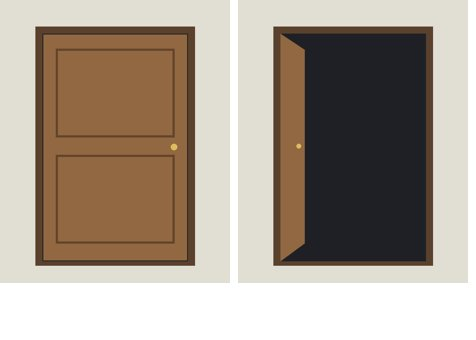

In [17]:
def door_image(opened):
    image = PILImage.new("RGB", (520, 640), (225, 222, 212))
    draw = ImageDraw.Draw(image)
    draw.rectangle((80, 60, 440, 600), fill=(90, 65, 45))
    draw.rectangle((96, 76, 424, 590), fill=(30, 32, 38))
    if opened:
        draw.polygon(((96, 76), (150, 112), (150, 550), (96, 590)),
                     fill=(145, 104, 65))
        draw.ellipse((132, 325, 142, 335), fill=(220, 188, 93))
    else:
        draw.rectangle((98, 78, 422, 588), fill=(145, 104, 65))
        draw.rectangle((126, 110, 394, 310), outline=(100, 68, 43), width=5)
        draw.rectangle((126, 350, 394, 550), outline=(100, 68, 43), width=5)
        draw.ellipse((386, 325, 400, 339), fill=(220, 188, 93))
    return image

CLOSED, OPEN = door_image(False), door_image(True)
FRAME_SEQUENCES = {"ended_closed": [CLOSED, OPEN, CLOSED],
                   "ended_open": [CLOSED, CLOSED, OPEN]}
preview([CLOSED, OPEN], width=230)

### 5.1 Score 明确编码 0、1、2

最新帧用两个问题交叉阅读：Noul 判断是否关闭，Score 衡量开合程度。
Score 的 0/1/2 是预先定义的有序档位，score 是概率加权期望；例如 0.12 不表示“门开了 12%”。

两个问题都看帧序列，并不读取彼此答案；二者一致也不能替代已知状态标签。

In [18]:
FRAME_QUESTIONS = {
    "closed": Noul(instructions="frames[2].frame 中最新一帧的门是完全关闭的吗？"),
    "openness": Score(instructions="只判断 frames[2].frame 中最新一帧门的开合程度。",
                      criteria=DOOR_LEVELS),
}
FRAME_RESULTS = {}
for label, frames in FRAME_SEQUENCES.items():
    state = {"frames": [{"seconds_ago": 2-i, "frame": asset(image, f"{label}_{i}")}
                        for i, image in enumerate(frames)]}
    FRAME_RESULTS[label] = call(label, state, FRAME_QUESTIONS).answers

### 5.2 同时展示 Score 分布与已知顺序

评估最新状态时使用 Noul 的固定 0.5 阈值；Score 的期望值辅助解释，不拿小数直接作精确开门比例。
若顺序变化后读数没有相应变化，应记录这次未识别最新帧，不能宣称帧序列实验已经成功。

In [19]:
FRAME_ROWS = []
for label, answers in FRAME_RESULTS.items():
    closed_expected = label == "ended_closed"
    score = answers["openness"]
    FRAME_ROWS.append({"序列": label, "最新应关闭": closed_expected,
        "P(关闭)": answers["closed"].noul,
        "最新状态命中": (answers["closed"].noul >= .5) == closed_expected,
        "开合期望值": score.score, "confidence": score.confidence})
    print(label, "legend=", score.legend, "probabilities=", score.probabilities)
table(FRAME_ROWS)

ended_closed legend= {0: '门完全关闭，门板遮住门洞。', 1: '门部分打开，仍有门板遮住部分门洞。', 2: '门完全打开，门洞基本敞开。'} probabilities= {0: 0.98, 1: 0.01, 2: 0.01}
ended_open legend= {0: '门完全关闭，门板遮住门洞。', 1: '门部分打开，仍有门板遮住部分门洞。', 2: '门完全打开，门洞基本敞开。'} probabilities= {0: 0.01, 1: 0.33, 2: 0.66}


| 序列 | 最新应关闭 | P(关闭) | 最新状态命中 | 开合期望值 | confidence |
|---|---|---|---|---|---|
| ended_closed | True | 0.98 | True | 0.04 | 0.95 |
| ended_open | False | 0.01 | True | 1.65 | 0.47 |

这只是有限帧集合上的最新状态判断。它没有检验连续视频理解、运动轨迹、帧间推理或“看过所有帧”。
想检查是否曾打开，应再设计含与不含打开帧的配对序列；本册没有声称覆盖这一分支。

## 6. 图片放置与 token：相同图片怎样共享

使用同一张咖啡馆照片和前面同样的两个任务。
A 将图放 state，两个问题引用它；B 将同一个 Image 对象分别放进两个问题的 instructions。

B 的文件可只上传一次，但图片引用出现在两个问题里；“上传次数”和“模型读取次数”不是同一个量。
两种请求的结构文字略有不同，下面比较的是总 input_tokens，不能把差值精确当成单张图片的固定 token 价格。

In [20]:
COST_IMAGE = PHOTO_ASSETS["cafe_selfie"]
DUPLICATE_QUESTIONS = {
    key: question.model_copy(update={"instructions": {
        "task": question.instructions, "photo": COST_IMAGE}})
    for key, question in PHOTO_QUESTIONS.items()
}
COST_SHARED = call("cost_shared", {"photo": COST_IMAGE}, PHOTO_QUESTIONS)
COST_DUPLICATE = call("cost_duplicate", {}, DUPLICATE_QUESTIONS)

### 6.1 返回用量与答案一起看

usage.input_tokens 包含图片、文本、问题结构等全部输入。图像按输入 token 计费；
本册只报告本次用量，不将它换算成固定价格或保证“共享一定省多少”。

In [21]:
COST_ROWS = [
    {"放置": label, "input_tokens": response.usage.input_tokens,
     "人脸概率": response.answers["face"].noul,
     "构图选择": response.answers["composition"].choice}
    for label, response in (("state 共享", COST_SHARED), ("instructions 重复", COST_DUPLICATE))
]
table(COST_ROWS)
token_delta = COST_DUPLICATE.usage.input_tokens - COST_SHARED.usage.input_tokens
print("逐问题放图 - state 共享 =", token_delta, "input_tokens")

| 放置 | input_tokens | 人脸概率 | 构图选择 |
|---|---|---|---|
| state 共享 | 3376 | 0.99 | person_photo |
| instructions 重复 | 6331 | 0.98 | person_photo |

逐问题放图 - state 共享 = 2955 input_tokens


这里没有比较两种不同照片或主观文字转述，因此修正了旧版“雨天描述 vs 咖啡馆自拍”的混杂对照。
但也没有精确拆分图片编码成本与结构文字成本，更不能从一次差值推导任意分辨率或帧数的 token 公式。

## 7. 协议负例：有意触发的拒绝与程序错误分开

使用同一张合规图片测试缺少危险区开关；另用 279×400 图片测试最小宽度，其他条件保持合规。
只接受对应的 HTTP 400 与明确错误原因，不能把超时、鉴权失败或本地文件找不到算成“拒绝验证成功”。

离线模式下面两次拒绝为人工模拟，会在记录中标注来源，不访问服务端。

In [22]:
def probe(label, image, headers, marker):
    if MODE == "offline":
        status, message = 400, f"人工模拟：{marker}"
    else:
        try:
            client.system_one({"photo": image}, {"face": PHOTO_QUESTIONS["face"]},
                              extra_headers=headers)
        except TypeSafeAPIError as error:
            status = error.status
            message = str(error)
            if KEY:
                message = message.replace(KEY, "[REDACTED]")
            message = message[:240]
            if status != 400 or marker.lower() not in message.lower():
                raise
        else:
            raise AssertionError("未出现预期的 HTTP 拒绝")
    PROBES.append({"label": label, "source": MODE, "status": status,
                   "expected_rejection": True, "message": message})
    print(label, "HTTP", status, "来源=", MODE)

### 7.1 分别执行两个负例

缺开关时的错误应提到 TypeSafe-Danger-Zone-Images；越界尺寸应明确为 dimensions。
这些探针只核对两条协议规则，未验证所有文件格式、上限、请求体或压缩限制。

In [23]:
probe("missing_header", PHOTO_ASSETS["cafe_selfie"], {},
      "TypeSafe-Danger-Zone-Images")
too_narrow = PILImage.new("RGB", (279, 400), (200, 200, 205))
probe("minimum_width", asset(too_narrow, "too_narrow", validate=False),
      HEADERS, "dimensions")
table(PROBES)

missing_header HTTP 400 来源= live


minimum_width HTTP 400 来源= live


| label | source | status | expected_rejection | message |
|---|---|---|---|---|
| missing_header | live | 400 | True | POST https://api.typesafe.ai/v1/systemone: 400 Images are experimental. Send the header TypeSafe-Danger-Zone-Images: true to use them. (request_id=req_01a1485dd7c8707eb30c8498c85d4594) |
| minimum_width | live | 400 | True | POST https://api.typesafe.ai/v1/systemone: 400 Invalid image dimensions. (request_id=req_01a1485dd967784696b30d3666f30f88) |

边界处使用 279 像素，不能沿用旧版“文档 256、实测约 280”的描述：当前文档已经明确最小值为 280。
图片宽高、总像素、文件字节和展开请求大小是不同约束，不能混为同一个“图片太大”。

## 8. 应用拼接：看见内容，再由用户选择回应目标

前面的模型输出只承担视觉识别。下面复用已有响应，按构图给出一个开放式询问模板，
再按用户明确选择的 celebrate/comfort/decline 配贴纸，不新增 API 请求。

这是一条可检查的代码策略；它没有从照片猜发送者的意图或情绪，也没有宣称模板适合所有对话。

In [24]:
TEMPLATES = {
    "person_photo": "看到你的照片了，今天有什么想分享的吗？",
    "food_table": "这一餐看起来很丰富，你最喜欢哪道？",
    "outdoor_scene": "这个地方很好看，是在哪里拍的？",
    "other": "这张照片有什么故事吗？",
}
STYLE_STICKER = {"celebrate": "bear_hug", "comfort": "rua_you", "decline": "ride_bear"}

def reply_preview(photo_key, reply_goal):
    answer = PHOTO_RESULTS[photo_key]["composition"]
    text = (TEMPLATES[answer.choice] if answer.confidence >= .6
            else "能再告诉我一点这张照片的背景吗？")
    sticker = STYLE_STICKER[reply_goal]
    return {"text": text, "sticker": sticker,
            "caption": MANIFEST["stickers"][sticker]["caption"]}

print(reply_preview("cafe_selfie", reply_goal="celebrate"))
print(reply_preview("sunset_chairs", reply_goal="comfort"))

{'text': '看到你的照片了，今天有什么想分享的吗？', 'sticker': 'bear_hug', 'caption': '绝了绝了'}
{'text': '这个地方很好看，是在哪里拍的？', 'sticker': 'rua_you', 'caption': '抱抱'}


0.6 只是演示阈值，未在业务开发集上选择。匹配贴纸的视觉能力和选择回复语气的业务策略是两件事，
后者由使用者明确提供。若要自动推荐语气，需要另外收集偏好标签并定义失败成本。

## 9. 旧结论为什么需要修订

旧版输出已保存到[文本归档](images_records/legacy-before-20261017.json)；旧文件没有完整请求来源记录。
本次修订撤回或纠正：

- 生图提示词不是发送者意图的真值；图片旁的 about 描述还混入了判断依据。
- 正文沿用了雨伞、告别、小厨房等旧素材；多处小数与保存输出不一致。
- 五张贴纸的文字描述与实际配字不符，不能继续用错误描述解释推荐结果。
- 一张图的亮度变化不能证明“表情比光线更重要”；旧实验没有表情变化对照。
- 原“弱/强锚点”同时改了 instructions 和 criteria，不能只归因于锚点；也不是校准评测。
- Score 列表从 0 编码，旧版把描述中的 1–5 当成了数值档位。
- 旧版 token 对照使用不同场景，且没有真正演示 instructions 内的图片。
- 任意 Exception 被当成预期尺寸拒绝、缺密钥/401 自动回退，都不足以支持真实验收。

本册保留有趣的素材，但只对实际测量的行为下结论。

## 10. 本次结果汇总

以下内容由本次输出生成；人工模式不能用于评价模型。
逐项看样本、负例、分布和成本，避免把“请求成功”当成“所有判断都正确”。

In [25]:
face_hits = sum(row["人脸命中"] for row in PHOTO_ROWS)
scene_hits = sum(row["构图命中"] for row in PHOTO_ROWS)
reference_hits = sum(row["命中"] for row in REFERENCE_ROWS)
sticker_hits = sum(row["命中"] for row in STICKER_ROWS)
frame_hits = sum(row["最新状态命中"] for row in FRAME_ROWS)
label = "真实 API：仅本次固定样本" if MODE == "live" else "人工示例，不能评价模型"
display(Markdown(
    f"**来源：{label}**\n\n"
    f"- 四张照片：人脸判断 {face_hits}/4，构图选择 {scene_hits}/4。\n"
    f"- instructions 参考图：{reference_hits}/2；criteria 图案匹配：{sticker_hits}/2。\n"
    f"- 同图三档亮度的人脸概率最大差值：{max(light_values)-min(light_values):.4f}。\n"
    f"- 两组顺序的最新帧状态命中：{frame_hits}/2。\n"
    f"- 重复放图与共享 state 的总 input_tokens 差值：{token_delta}。\n"
    f"- 预期 HTTP 拒绝探针完成 {len(PROBES)}/2。"))

**来源：真实 API：仅本次固定样本**

- 四张照片：人脸判断 4/4，构图选择 4/4。
- instructions 参考图：2/2；criteria 图案匹配：2/2。
- 同图三档亮度的人脸概率最大差值：0.0000。
- 两组顺序的最新帧状态命中：2/2。
- 重复放图与共享 state 的总 input_tokens 差值：2955。
- 预期 HTTP 拒绝探针完成 2/2。

### 2026-10-17 已归档的实测观察

本段对应[真实记录](images_records/live-20261017.json)：15 次业务请求、23 个问题，
另有 2 次预期 HTTP 400；所有成功响应均为 jev-1.14.0，无离线回退。重新运行时应同时查看上方动态汇总。

| 检查 | 本次观察 | 解释范围 |
|---|---|---|
| 照片可见事实 | 人脸 4/4，构图 4/4 | 四张固定生成素材上的标签核对，不是通用准确率 |
| instructions 参考图 | 相同图案 0.99，不同图案 0.01 | 两个简单关系样本，不代表开放场景比较能力 |
| criteria 图案匹配 | 已知贴纸选 bear_hug；不匹配图选 none | 本候选集命中，未证明图片优于文字选项 |
| 同图亮度探针 | 三档 P(人脸) 均为 0.99 | 本任务未观察到变化，不支持关于情绪的结论 |
| 最新帧 | 关闭序列 P(关闭)=0.98；打开序列=0.01 | 这对顺序样本被区分，不代表视频或运动理解 |
| 打开帧的 Score | 期望 1.65，P(半开)=0.33、P(全开)=0.66，confidence=0.47 | 模型在开合等级间仍有分歧，不能只看最新状态命中就说量表完全可靠 |
| 同图放置与成本 | state 共享 3376，instructions 重复 6331 input tokens | 本对请求差 2955 tokens，包含结构文字，不是固定图片 token 单价 |
| 协议负例 | 缺开关与宽 279 图片均返回对应 HTTP 400 | 只验证这两条规则，未遍历所有格式和大小边界 |

逐格核对了响应、画面、概率分布和应用模板；没有增加独立金标、重复测量或校准证据。

### 仍不能得出的结论

没有代表线上分布的独立测试集、重复测量或校准数据，不能报告总体准确率、情绪理解、
对发送者意图的可靠推断、跨语言收益或任意分辨率的 token 估算公式。
本册的目标是接口与实验设计；准确率与概率质量的系统评估见第六章。

### 执行来源记录

记录保存实际模型、素材版本、每次请求的证据位置、问题、响应与预期拒绝。
真实执行不得出现人工回退；离线输出另存 validation/images，避免覆盖正式实测。

In [26]:
AUDIT = {
    "kind": "jev_images_execution_audit", "run_mode": MODE,
    "finished_at_utc": datetime.now(timezone.utc).isoformat(),
    "requested_model": MODEL, "sdk_version": version("typesafe-sdk"),
    "manifest_version": MANIFEST["version"],
    "manifest_sha256": hashlib.sha256(
        (CHAPTER / "scenes/images_manifest.json").read_bytes()).hexdigest(),
    "real_calls": sum(c["source"] == "live" for c in CALLS),
    "offline_calls": sum(c["source"] == "offline" for c in CALLS),
    "real_probe_calls": sum(p["source"] == "live" for p in PROBES),
    "results": {"photos": PHOTO_ROWS, "reference": REFERENCE_ROWS,
                "stickers": STICKER_ROWS, "brightness": LIGHT_ROWS,
                "frames": FRAME_ROWS, "token_placement": COST_ROWS},
    "calls": CALLS, "probes": PROBES,
}
if client is not None:
    client.close()
print(json.dumps(AUDIT, ensure_ascii=False, indent=2))

{
  "kind": "jev_images_execution_audit",
  "run_mode": "live",
  "finished_at_utc": "2026-10-17T05:37:52.335748+00:00",
  "requested_model": "jev-1.14.0",
  "sdk_version": "0.7.5",
  "manifest_version": "2026-10-17-v1",
  "manifest_sha256": "a7ea7012ec99a9daffe2e05d2a13102ce500199a9da01936824fdd715ffd3cdc",
  "real_calls": 15,
  "offline_calls": 0,
  "real_probe_calls": 2,
  "results": {
    "photos": [
      {
        "素材": "cafe_selfie",
        "P(人脸)": 0.99,
        "人脸标签": true,
        "人脸命中": true,
        "构图选择": "person_photo",
        "构图标签": "person_photo",
        "构图命中": true,
        "confidence": 1.0
      },
      {
        "素材": "overtime_night",
        "P(人脸)": 0.99,
        "人脸标签": true,
        "人脸命中": true,
        "构图选择": "person_photo",
        "构图标签": "person_photo",
        "构图命中": true,
        "confidence": 1.0
      },
      {
        "素材": "brunch_table",
        "P(人脸)": 0.01,
        "人脸标签": false,
        "人脸命中": true,
        "构图选择": "food_table",
   

## 下一步

改变一个因素前，先保存问题、素材与预期，保留失败输出；不要看完结果才挑成功案例。
有了 state / instructions / criteria 三种图像位置，下一册会把问题推进到“目标在哪里”。

[第二章目录](README.md) · [07 Box 定位](07_box定位.ipynb) ·
[第六章评测](../06_模型评测/README.md) · [官方 Images](https://docs.typesafe.ai/images)